# Backtesting Systematic Strategies Without Fooling Yourself

Trend following is the strategy behind managed-futures funds (CTAs). It is also the
easiest strategy to backtest badly. This notebook builds a small backtesting engine and
uses it on 12 futures markets over 20 years, with three rules I enforce everywhere:

1. **No look-ahead.** A signal computed at today's close is traded tomorrow.
2. **Costs are charged.** 2 bp per unit of turnover, so a fast strategy has to earn its trading.
3. **Overfitting is measured.** Trying many lookbacks and keeping the best one inflates the
   Sharpe ratio; the Deflated Sharpe Ratio corrects for it.

The market data are simulated with slowly changing hidden trends (a trend worth a Sharpe of
about 0.9 per market, hidden under daily noise), plus a pure random-walk version for comparison.

In [1]:
import os, sys, subprocess
if "google.colab" in sys.modules and not os.path.exists("backtest.py"):
    subprocess.run(["git", "clone", "-q", "https://github.com/adamrejeb86-del/-finance-portfolio.git"], check=True)
    os.chdir("-finance-portfolio/19-systematic-strategy-backtester")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from backtest import (MARKETS, simulate_markets, tsmom_signal, ma_crossover_signal, xs_momentum_signal, long_only_signal,
                      run_backtest, stats, deflated_sharpe)

plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})
NAVY, BORDEAUX, GREY, TEAL, GOLD = "#1f3b5c", "#7a1f2b", "#8a8a8a", "#2a7f7f", "#b08d3c"
R = simulate_markets(252 * 20, seed=7)
pd.DataFrame({"Annual vol": R.std() * np.sqrt(252), "Annual return": R.mean() * 252}, index=MARKETS).T.round(3)

,S&P 500,Euro Stoxx 50,Nikkei 225,US 10Y,Bund,JGB,EUR/USD,USD/JPY,GBP/USD,Gold,Crude oil,Copper
Annual vol,0.172,0.200,0.213,0.060,0.055,0.030,0.079,0.091,0.086,0.157,0.323,0.243
Annual return,0.001,-0.128,0.055,0.008,0.006,0.018,0.005,0.013,0.016,0.072,0.075,-0.032


## 1. Four strategies

| Strategy | Rule |
|---|---|
| Time-series momentum (12m) | long a market if its past 12-month return is positive, short otherwise |
| Time-series momentum (6m) | same with a 6-month lookback |
| MA crossover | long if the 50-day average is above the 200-day average |
| Cross-sectional momentum | long the best third of markets, short the worst third (risk-adjusted 12m return) |
| Long-only, equal risk | benchmark |

Every market is sized to the same volatility (EWMA, 60-day half-life), positions are
rebalanced weekly, and the whole book is scaled to a 10% volatility target.

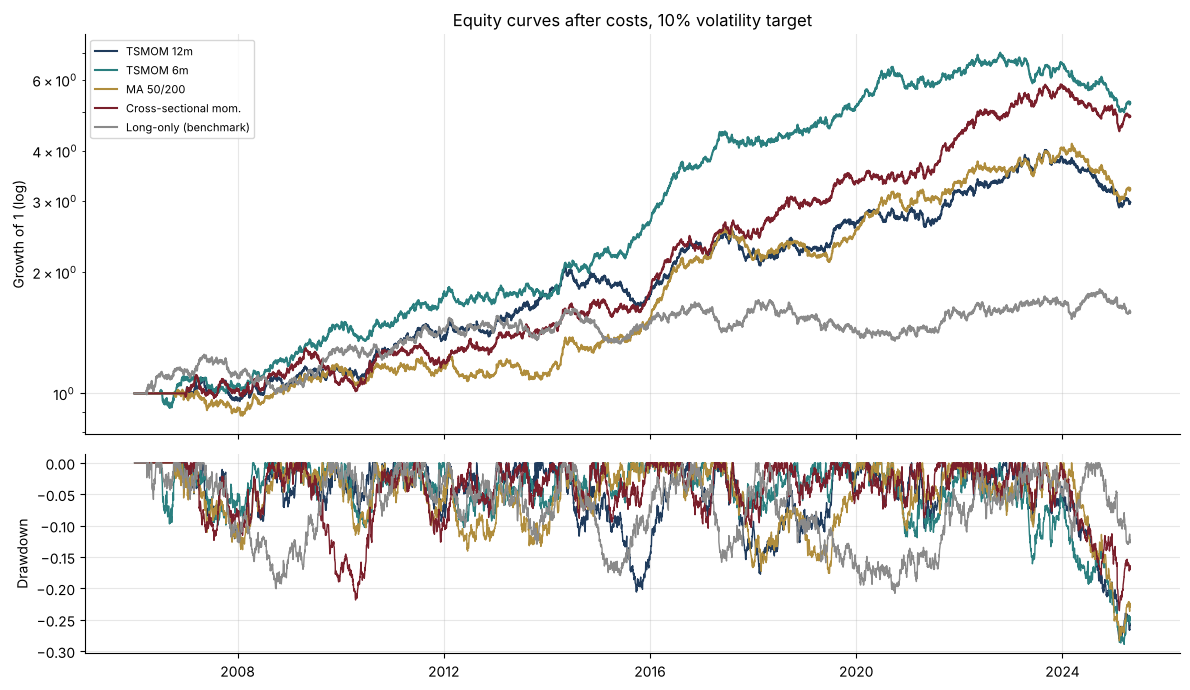

,CAGR,Volatility,Sharpe,Sortino,Max drawdown,Calmar,Skewness,Hit rate,Turnover (x/yr)
TSMOM 12m,5.9%,10.2%,0.61,0.89,-28.0%,0.21,-0.05,51.4%,30
TSMOM 6m,8.9%,10.2%,0.88,1.30,-28.9%,0.31,-0.03,52.4%,36
MA 50/200,6.3%,10.3%,0.64,0.94,-28.4%,0.22,0.00,51.9%,18
Cross-sectional mom.,8.7%,10.1%,0.87,1.27,-23.6%,0.37,-0.15,53.0%,35
Long-only (benchmark),2.4%,10.2%,0.28,0.40,-20.8%,0.11,-0.01,51.2%,5


In [2]:
signals = {"TSMOM 12m": tsmom_signal(R, 252), "TSMOM 6m": tsmom_signal(R, 126), "MA 50/200": ma_crossover_signal(R),
           "Cross-sectional mom.": xs_momentum_signal(R), "Long-only (benchmark)": long_only_signal(R)}
results = {name: run_backtest(R, sig, cost_bps=2.0) for name, sig in signals.items()}
table = pd.DataFrame({name: stats(res["returns"], res["turnover"]) for name, res in results.items()}).T
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
for (name, res), c in zip(results.items(), [NAVY, TEAL, GOLD, BORDEAUX, GREY]):
    w = (1 + res["returns"]).cumprod()
    axes[0].plot(w.index, w, color=c, lw=1.5, label=name)
    axes[1].plot(w.index, w / w.cummax() - 1, color=c, lw=1)
axes[0].set(yscale="log", ylabel="Growth of 1 (log)", title="Equity curves after costs, 10% volatility target"); axes[0].legend(fontsize=8)
axes[1].set(ylabel="Drawdown")
plt.tight_layout(); plt.savefig("images/equity_curves.png", dpi=150); plt.show()
table.style.format({"CAGR": "{:.1%}", "Volatility": "{:.1%}", "Sharpe": "{:.2f}", "Sortino": "{:.2f}", "Max drawdown": "{:.1%}",
                    "Calmar": "{:.2f}", "Skewness": "{:.2f}", "Hit rate": "{:.1%}", "Turnover (x/yr)": "{:.0f}"})

**What the table says.** All trend strategies beat the long-only benchmark on a risk-adjusted
basis, and they do it with a hit rate barely above 50%: trend following wins by letting a
few large trends run, not by being right often. The faster signal (6m) catches more trends
here but trades more.

## 2. Where the money comes from: crisis alpha

Trend followers are known for doing well when the equity market falls hard. Grouping the
months by the S&P 500's return shows that convexity.

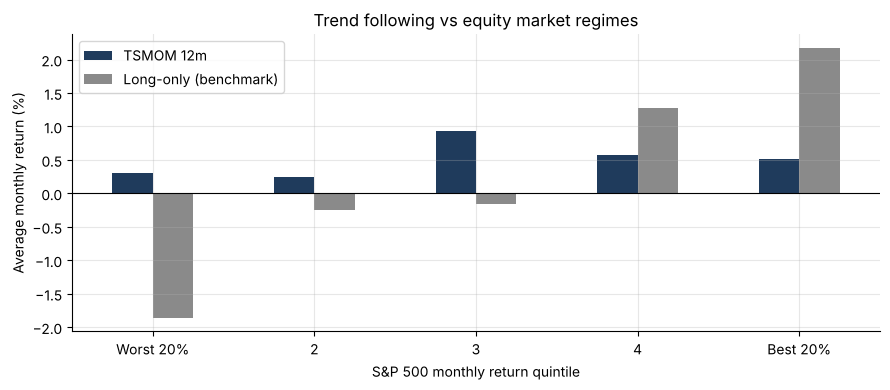

In [3]:
monthly = pd.DataFrame({name: (1 + res["returns"]).resample("ME").prod() - 1 for name, res in results.items()})
eq = (1 + R["S&P 500"]).resample("ME").prod() - 1
buckets = pd.qcut(eq, 5, labels=["Worst 20%", "2", "3", "4", "Best 20%"])
by_bucket = monthly.groupby(buckets, observed=True)[["TSMOM 12m", "Long-only (benchmark)"]].mean() * 100
ax = by_bucket.plot.bar(color=[NAVY, GREY], figsize=(9, 4), rot=0)
ax.axhline(0, color="black", lw=0.8); ax.set_ylabel("Average monthly return (%)")
ax.set_xlabel("S&P 500 monthly return quintile"); ax.set_title("Trend following vs equity market regimes")
plt.tight_layout(); plt.savefig("images/crisis_alpha.png", dpi=150); plt.show()

## 3. Costs change the ranking

The same strategies with costs from 0 to 10 bp per unit traded. At 10 bp, 12-month time-series
momentum loses almost half of its Sharpe ratio, while the moving-average crossover, which
trades the least, holds up best. A strategy's turnover matters as much as its signal.

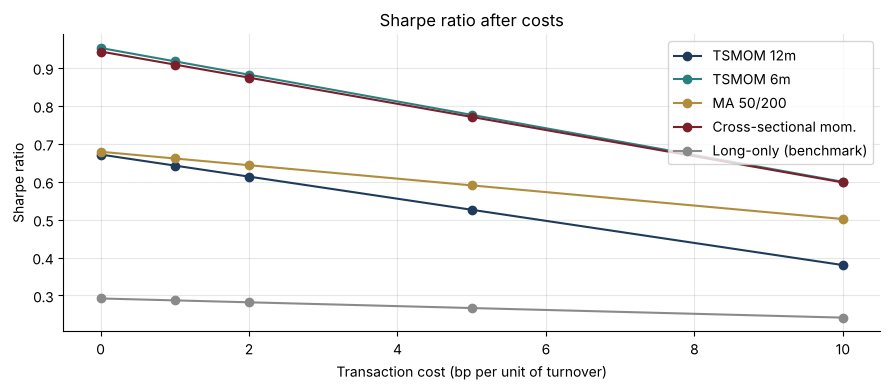

In [4]:
costs = [0, 1, 2, 5, 10]
sr_cost = pd.DataFrame({c: {name: stats(run_backtest(R, sig, cost_bps=c)["returns"])["Sharpe"] for name, sig in signals.items()}
                        for c in costs})
ax = sr_cost.T.plot(marker="o", figsize=(9, 4), color=[NAVY, TEAL, GOLD, BORDEAUX, GREY])
ax.set(xlabel="Transaction cost (bp per unit of turnover)", ylabel="Sharpe ratio", title="Sharpe ratio after costs")
plt.tight_layout(); plt.savefig("images/costs.png", dpi=150); plt.show()

## 4. Overfitting: how many backtests did you try?

I test 20 lookbacks (1 to 20 months) and keep the best. To see how much of the best Sharpe
could be luck, I run the exact same search on **random walks without any trend**. Then the
Deflated Sharpe Ratio gives the probability that the best result is genuine, given how many
variants were tried.

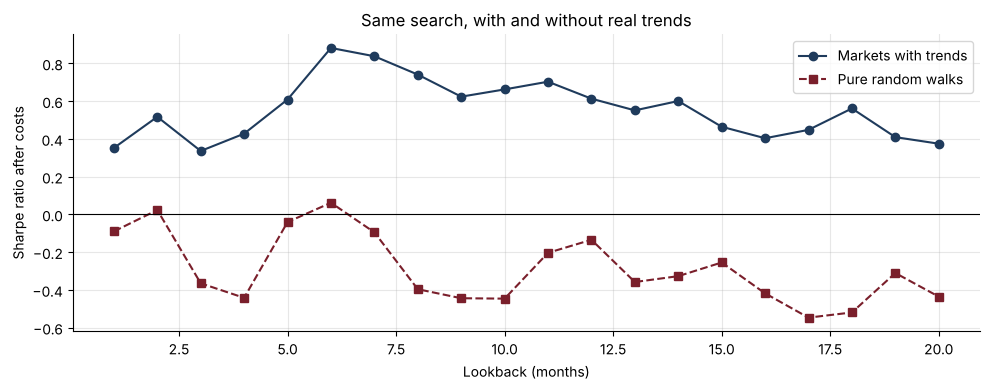

Trending markets : best lookback  6m, Sharpe 0.88, luck threshold 0.30, probability it is genuine 99%
Random walks     : best lookback  6m, Sharpe 0.06, luck threshold 0.35, probability it is genuine 11%


In [5]:
lookbacks = np.arange(21, 21 * 21, 21)
def sharpe_by_lookback(data):
    return np.array([stats(run_backtest(data, tsmom_signal(data, lb))["returns"])["Sharpe"] for lb in lookbacks])

sr_trend = sharpe_by_lookback(R)
R_noise = simulate_markets(252 * 20, trend_strength=0.0, seed=7)
sr_noise = sharpe_by_lookback(R_noise)
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(lookbacks / 21, sr_trend, "o-", color=NAVY, label="Markets with trends")
ax.plot(lookbacks / 21, sr_noise, "s--", color=BORDEAUX, label="Pure random walks")
ax.axhline(0, color="black", lw=0.8)
ax.set(xlabel="Lookback (months)", ylabel="Sharpe ratio after costs", title="Same search, with and without real trends"); ax.legend()
plt.tight_layout(); plt.savefig("images/overfitting.png", dpi=150); plt.show()

n_obs = len(R) - 300
for label, srs, data in [("Trending markets", sr_trend, R), ("Random walks", sr_noise, R_noise)]:
    best = int(np.argmax(srs))
    r_best = run_backtest(data, tsmom_signal(data, lookbacks[best]))["returns"].iloc[300:]
    p, sr0 = deflated_sharpe(srs[best] / np.sqrt(252), srs / np.sqrt(252), n_obs, r_best.skew(), r_best.kurt() + 3)
    print(f"{label:17s}: best lookback {lookbacks[best] // 21:2d}m, Sharpe {srs[best]:.2f}, "
          f"luck threshold {sr0 * np.sqrt(252):.2f}, probability it is genuine {p:.0%}")

On random walks, the best of 20 lookbacks still shows a positive Sharpe ratio: that is the
backtest overfitting trap. The Deflated Sharpe Ratio sets a "luck threshold" from the
dispersion of the trials and rejects that result, while the trending markets pass.

## Conclusions
- The engine enforces a one-day execution lag (a test changes future returns and checks
  that past positions do not move), charges costs on turnover and targets volatility.
- Trend following delivers its returns with a low hit rate and positive returns in the
  worst equity months.
- Costs and multiple testing are the two ways a backtest lies; both are measured here.
- **Next steps:** real futures data with roll adjustments, walk-forward parameter selection,
  and combining trend with carry.